# 1. Исходные данные и трёхмерная визуализация

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from pathlib import Path

DATA_PATH = Path("../Datasets/csv/HW.csv")
pics_save = Path("../Pics/HW")
pics_save.mkdir(parents=True, exist_ok=True)

df = pd.read_csv(DATA_PATH)

print("Размерность выборки:", df.shape)
display(df.head())

print("\nПропущенные значения:")
display(df.isna().sum())

print("Совпадающих строк:", df.duplicated().sum())
display(df.describe())

Размерность выборки: (115, 4)


,Position,Height(inches),Weight(pounds),Age
0,101.0,74.0,180.0,22.99
1,101.0,74.0,215.0,34.69
2,101.0,72.0,210.0,30.78
3,102.0,72.0,210.0,35.43
4,102.0,73.0,188.0,35.71



Пропущенные значения:


Position          0
Height(inches)    0
Weight(pounds)    0
Age               0
dtype: int64

Совпадающих строк: 12


,Position,Height(inches),Weight(pounds),Age
count,115.000000,115.000000,115.000000,115.000000
mean,103.165217,73.895652,204.191304,28.552174
std,1.388742,2.157703,20.234977,4.128190
min,101.000000,68.000000,160.000000,22.020000
25%,102.000000,73.000000,188.000000,25.110000
50%,103.000000,74.000000,205.000000,27.940000
75%,104.000000,75.000000,220.000000,31.475000
max,105.000000,81.000000,270.000000,37.740000


In [ ]:
numeric_features = df[["Height(inches)", "Weight(pounds)", "Age"]] # Три количественных признака
 
position_ohe = pd.get_dummies(df["Position"].astype(int).astype(str),prefix="Position",dtype=int) # Преобразуем коды позиций в категории и применяем OHE

print("Результаты One-Hot Encoding:")
display(position_ohe.head())

Результаты One-Hot Encoding:


,Position_101,Position_102,Position_103,Position_104,Position_105
0,1,0,0,0,0
1,1,0,0,0,0
2,1,0,0,0,0
3,0,1,0,0,0
4,0,1,0,0,0


In [ ]:
from sklearn.preprocessing import StandardScaler


scaler = StandardScaler()

numeric_scaled = pd.DataFrame(scaler.fit_transform(numeric_features),columns=numeric_features.columns,index=df.index) ## Приведение числовых признаков к нулевому среднему и единичному отклонению


X_hw = pd.concat([numeric_scaled, position_ohe],axis=1) # стандартизированные числа и бинарные столбцы Position

print("Размерность после OHE:", X_hw.shape)
display(X_hw.head())

Размерность после OHE: (115, 8)


,Height(inches),Weight(pounds),Age,Position_101,Position_102,Position_103,Position_104,Position_105
0,0.048572,-1.200751,-1.353260,1,0,0,0,0
1,0.048572,0.536497,1.493315,1,0,0,0,0
2,-0.882396,0.288318,0.542023,1,0,0,0,0
3,-0.882396,0.288318,1.673355,0,1,0,0,0
4,-0.416912,-0.803666,1.741478,0,1,0,0,0


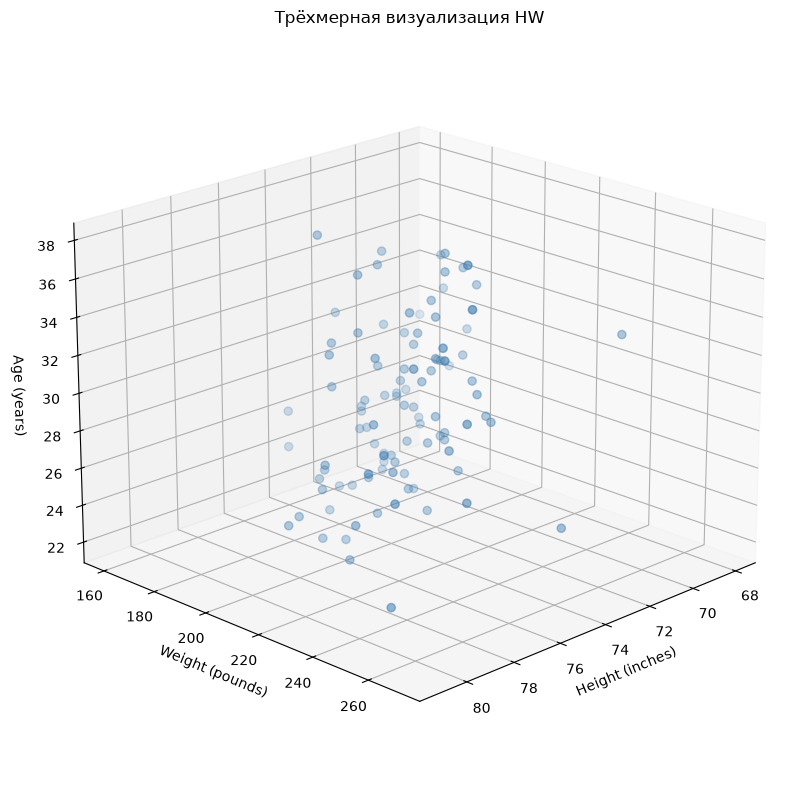

In [4]:
fig = plt.figure(figsize=(10, 8))
ax = fig.add_subplot(111, projection="3d")

ax.scatter(df["Height(inches)"],df["Weight(pounds)"],df["Age"],color="steelblue",s=35,alpha=0.75)
ax.set_title("Трёхмерная визуализация HW")
ax.set_xlabel("Height (inches)")
ax.set_ylabel("Weight (pounds)")
ax.set_zlabel("Age (years)")
ax.view_init(elev=20, azim=45)

plt.tight_layout()

fig.savefig(pics_save / "1_3d_hw.png",dpi=300,  bbox_inches="tight")

plt.show()

# 2. Иерархическая кластеризация

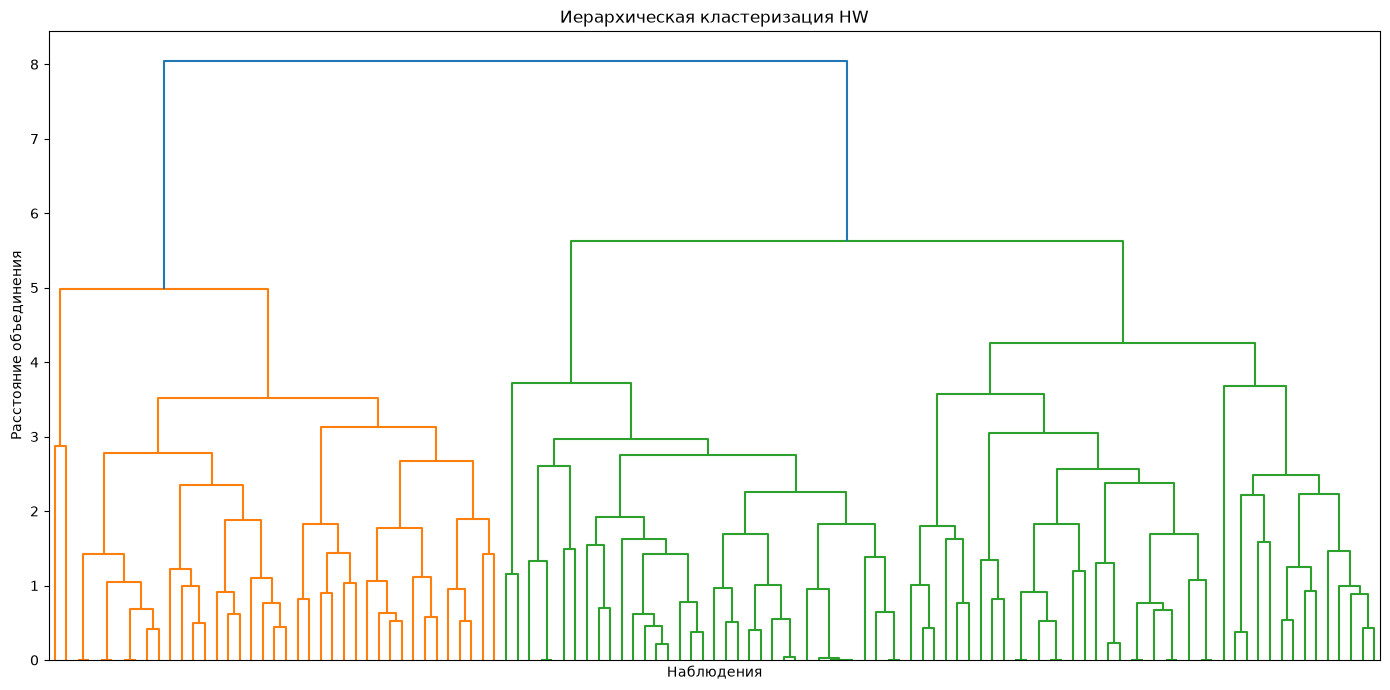

In [ ]:
from scipy.cluster.hierarchy import linkage, dendrogram
import matplotlib.pyplot as plt


Z_complete = linkage(X_hw,method="complete",metric="euclidean") # иерархия методом полной связи с евклидовым расстоянием


fig, ax = plt.subplots(figsize=(14, 7))

dendrogram(Z_complete,no_labels=True,ax=ax)# последовательность объединений без подписей объектов

ax.set_title("Иерархическая кластеризация HW")
ax.set_xlabel("Наблюдения")
ax.set_ylabel("Расстояние объединения")
plt.tight_layout()
fig.savefig(pics_save / "2_1_dendrogram_complete.png",dpi=300,bbox_inches="tight")

plt.show()

In [ ]:
from scipy.cluster.hierarchy import linkage, dendrogram
import matplotlib.pyplot as plt

metrics = {"Евклидово": "euclidean","Манхэттенское": "cityblock","Чебышева": "chebyshev","Косинусное": "cosine"} # меры расстояния между наблюдениями
methods = {"Одиночная": "single","Полная": "complete","Средняя": "average","Центроидная": "centroid","Уорда": "ward"} # правила объединения кластеров
results_hw = {}

for metric_name, metric in metrics.items():# сочетания мер расстояния и методов связи
    for method_name, method in methods.items():
        if method in ["centroid", "ward"] and metric != "euclidean": # # Методы Уорда и центроидный применяем только с евклидовой метрикой
            continue
        Z_current = linkage(X_hw,method=method,metric=metric)# Вычисление иерархии для допустимого сочетания
        results_hw[(metric_name, method_name)] = Z_current
print("Количество комбинаций:", len(results_hw))

Количество комбинаций: 14


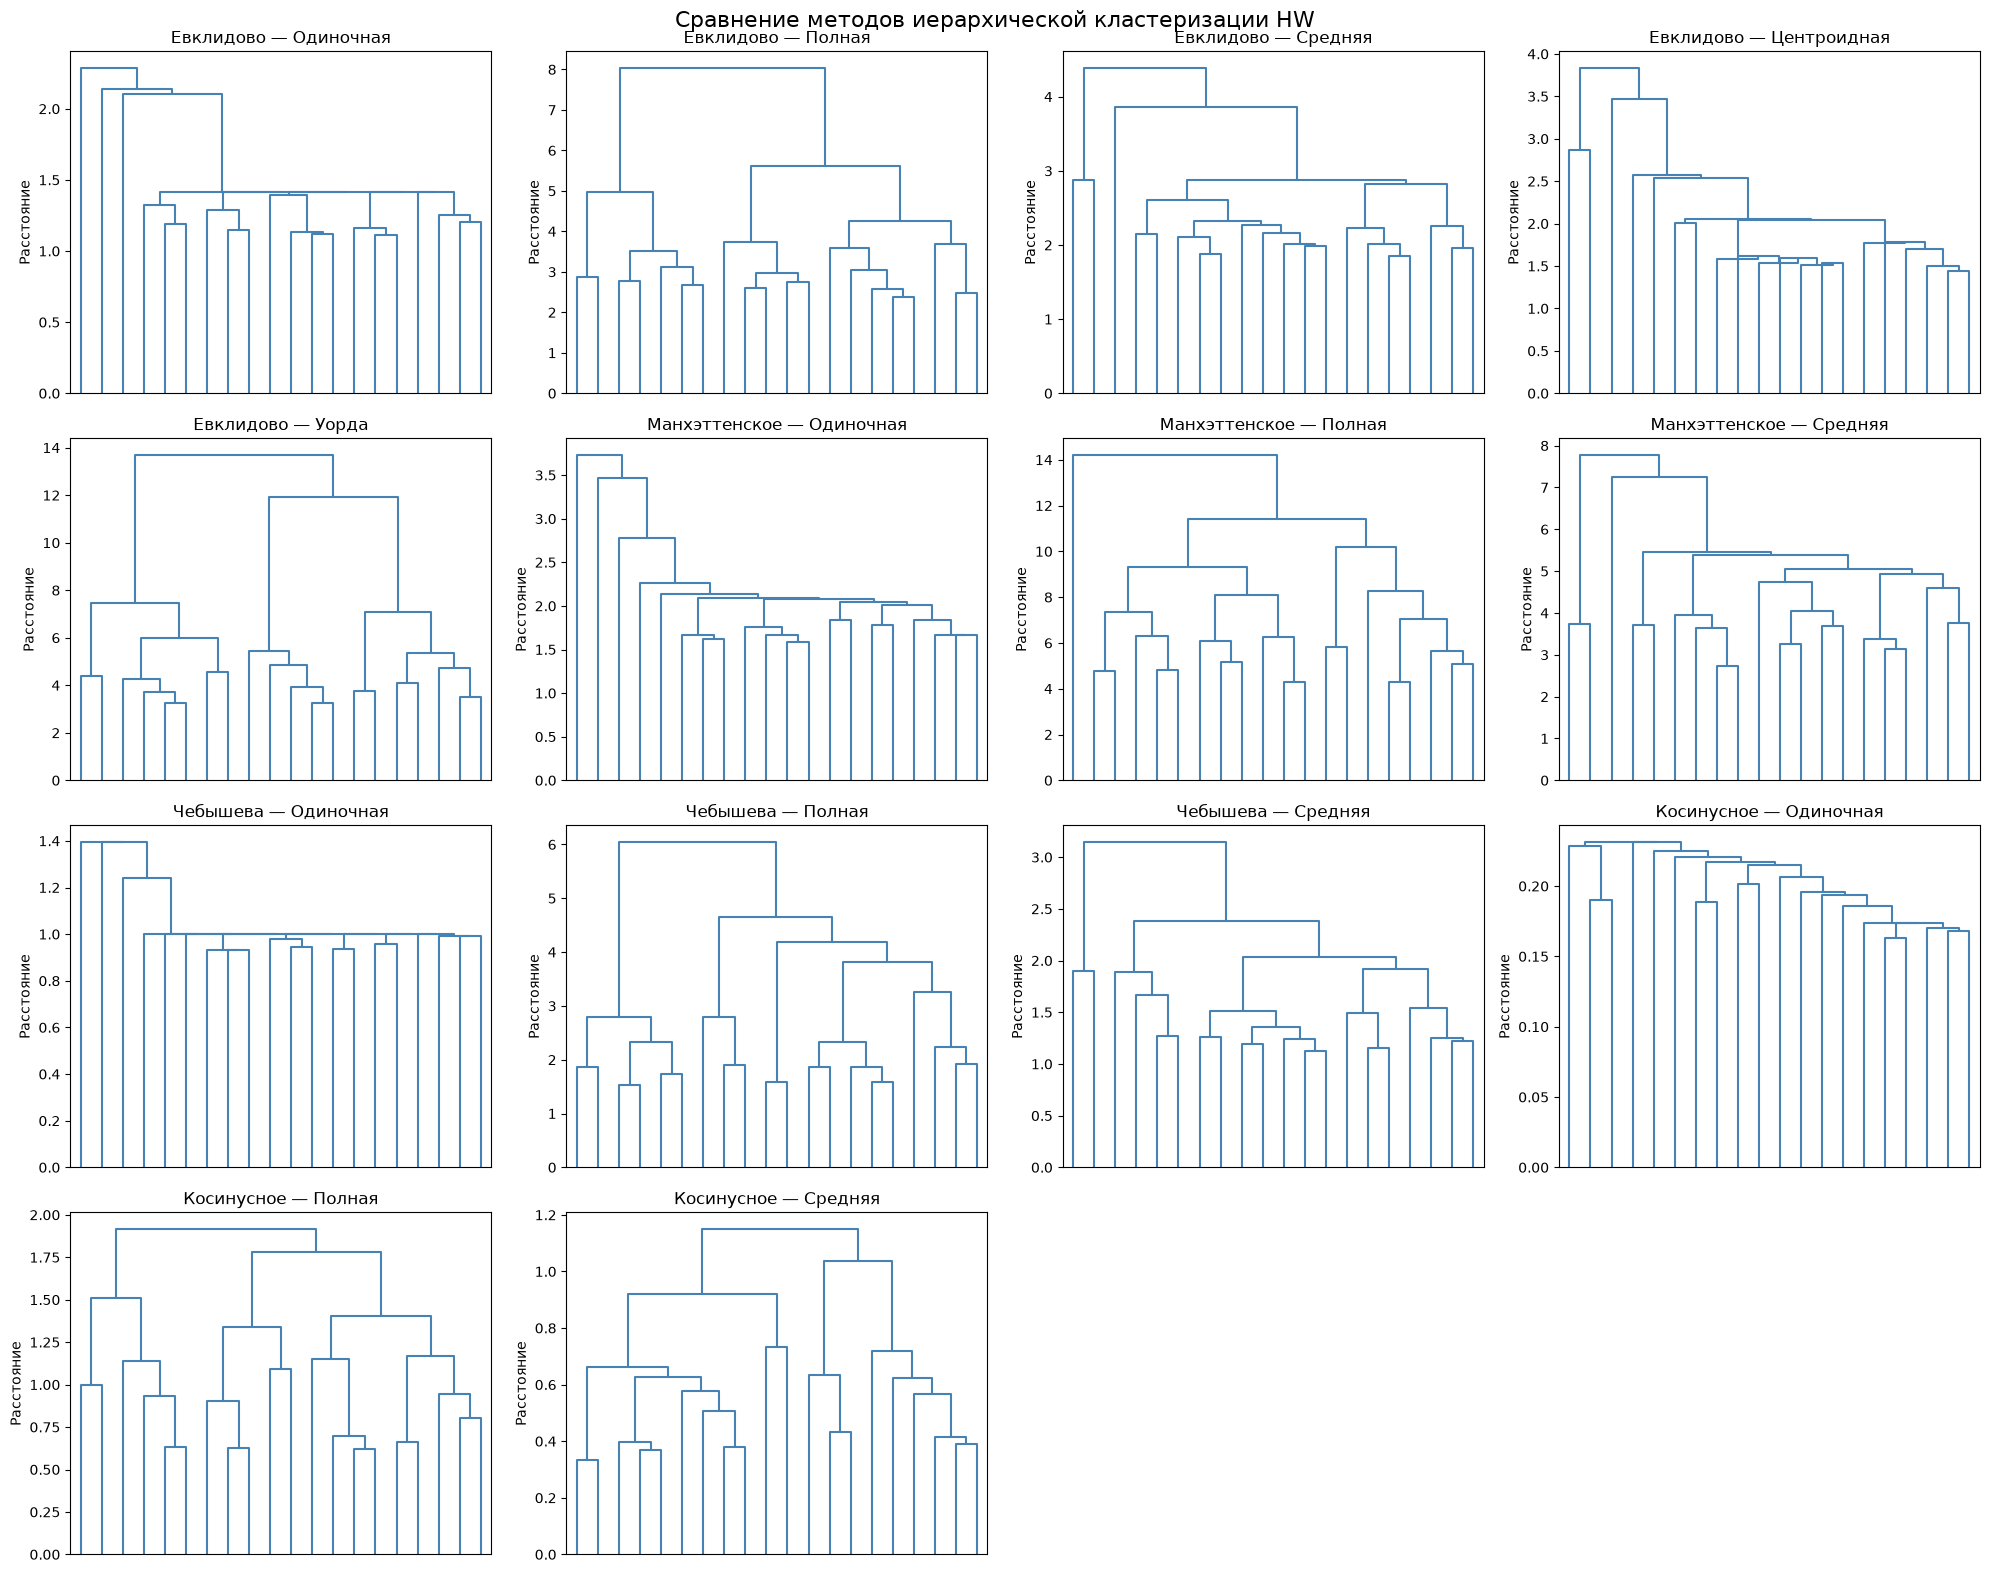

In [ ]:
fig, axes = plt.subplots(4, 4, figsize=(20, 16))
axes = axes.flatten()

for ax, ((metric_name, method_name), Z_current) in zip(axes, results_hw.items()):
    dendrogram(Z_current, truncate_mode="lastp", p=20, no_labels=True, color_threshold=0, above_threshold_color="steelblue", ax=ax) # построение  дендрограммы для сочетания
    ax.set_title(f"{metric_name} — {method_name}")
    ax.set_ylabel("Расстояние")
for ax in axes[len(results_hw):]:
    ax.axis("off")

fig.suptitle("Сравнение методов иерархической кластеризации HW",fontsize=16)
plt.tight_layout()
fig.savefig(pics_save / "2_hierarchical_comparison.png",dpi=300,bbox_inches="tight")

plt.show()

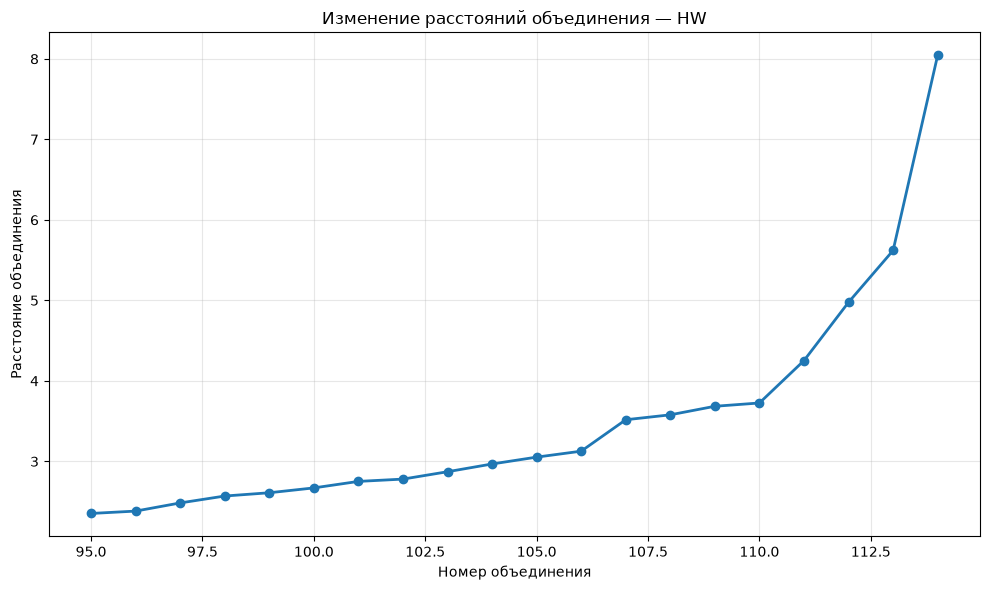

,Номер объединения,Расстояние
104,105,3.053
105,106,3.127
106,107,3.517
107,108,3.578
108,109,3.684
109,110,3.725
110,111,4.252
111,112,4.976
112,113,5.620
113,114,8.045


In [ ]:
import numpy as np
import pandas as pd

Z_complete = results_hw[("Евклидово", "Полная")] #  результаты евклидовой метрики и полной связи
distances = Z_complete[:, 2] # расстояния объединений 
n_last = 20
steps = np.arange(len(distances) - n_last + 1,len(distances) + 1)# номера объединений для горизонтальной оси
fig, ax = plt.subplots(figsize=(10, 6))
ax.plot(steps,distances[-n_last:],marker="o",linewidth=2) # линия изменения расстояний с маркерами
ax.set_title("Изменение расстояний объединения — HW")
ax.set_xlabel("Номер объединения")
ax.set_ylabel("Расстояние объединения")
ax.grid(True, alpha=0.3)
plt.tight_layout()
fig.savefig(pics_save / "2_3_merge_distances.png",dpi=300,bbox_inches="tight")

plt.show()

display(pd.DataFrame({ "Номер объединения": np.arange(1, len(distances) + 1),"Расстояние": distances}).tail(10).round(3))

# 3. Метод главных компонент (PCA)

In [ ]:
from sklearn.decomposition import PCA
import numpy as np
import pandas as pd

pca_hw = PCA()

X_pca_hw = pca_hw.fit_transform(X_hw)# главные компоненты для подготовленных восьми признаков

explained_variance = pca_hw.explained_variance_ratio_ #доля дисперсии каждой компоненты

variance_df = pd.DataFrame({"Компонента": [f"PC{i + 1}" for i in range(len(explained_variance))],"Доля дисперсии": explained_variance, "Накопленная доля": np.cumsum(explained_variance)})

display(variance_df.round(4))

,Компонента,Доля дисперсии,Накопленная доля
0,PC1,0.4004,0.4004
1,PC2,0.2868,0.6872
2,PC3,0.1258,0.8130
3,PC4,0.0601,0.8731
4,PC5,0.0523,0.9254
5,PC6,0.0423,0.9677
6,PC7,0.0323,1.0000
7,PC8,0.0000,1.0000


In [ ]:
retained_variance = explained_variance[:2].sum() * 100 #процент дисперсии, сохранённый первыми двумя компонентами

lost_variance = 100 - retained_variance # # Нахождение оставшейся доли дисперсии

print(f"Сохранённая дисперсия: {retained_variance:.2f}%")
print(f"Потерянная дисперсия: {lost_variance:.2f}%")

Сохранённая дисперсия: 68.72%
Потерянная дисперсия: 31.28%


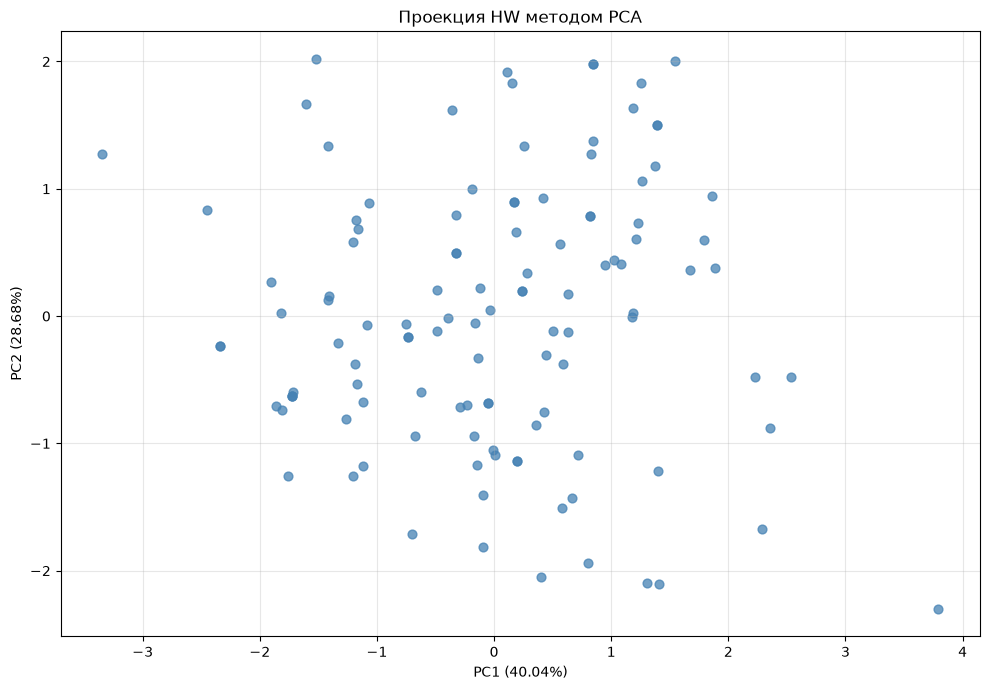

In [ ]:
fig, ax = plt.subplots(figsize=(10, 7))

ax.scatter(X_pca_hw[:, 0],X_pca_hw[:, 1],color="steelblue", s=40,alpha=0.75)# наблюдения в координатах PC1 и PC2
ax.set_title("Проекция HW методом PCA")
ax.set_xlabel(f"PC1 ({explained_variance[0] * 100:.2f}%)")
ax.set_ylabel( f"PC2 ({explained_variance[1] * 100:.2f}%)")
ax.grid(True, alpha=0.3)

plt.tight_layout()

fig.savefig(pics_save / "3_pca_projection.png",dpi=300,bbox_inches="tight")

plt.show()

In [ ]:
components_df = pd.DataFrame(pca_hw.components_[:2].T,index=X_hw.columns,columns=["PC1", "PC2"])# коэффициенты первых двух компонент с исходными признаками

display(components_df.round(4))

,PC1,PC2
Height(inches),0.6235,-0.4970
Weight(pounds),0.7135,0.1156
Age,0.2836,0.8515
Position_101,0.0011,0.0612
Position_102,-0.0223,0.0208
Position_103,-0.1105,0.0465
Position_104,0.0788,-0.0658
Position_105,0.0530,-0.0627


# 4. Метод t-SNE

In [ ]:
from sklearn.manifold import TSNE

tsne_hw = TSNE(n_components=2,perplexity=30, learning_rate="auto", init="pca", random_state=42)#модель t-SNE для двумерной проекции

X_tsne_hw = tsne_hw.fit_transform(X_hw)#координаты наблюдений после t-SNE

print("Размерность после t-SNE:", X_tsne_hw.shape)

Размерность после t-SNE: (115, 2)


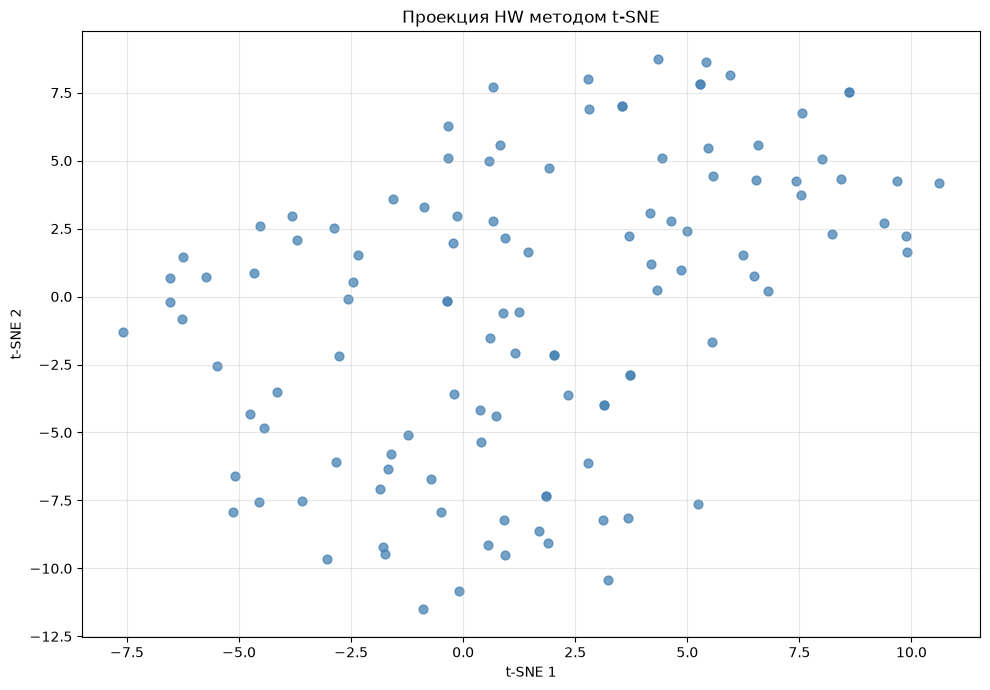

In [ ]:
fig, ax = plt.subplots(figsize=(10, 7))

ax.scatter(X_tsne_hw[:, 0], X_tsne_hw[:, 1], color="steelblue",s=40,alpha=0.75)# расположение наблюдений в пространстве t-SNE
ax.set_title("Проекция HW методом t-SNE")
ax.set_xlabel("t-SNE 1")
ax.set_ylabel("t-SNE 2")
ax.grid(True, alpha=0.3)

plt.tight_layout()

fig.savefig(pics_save / "4_tsne_projection.png",dpi=300,bbox_inches="tight")

plt.show()

# 6. Кластеризация методом K-means

In [ ]:
from sklearn.cluster import KMeans
import pandas as pd
import numpy as np

k_values = [1, 2, 3] #кластер для проверки гипотезы

kmeans_results_hw = {}

for k in k_values: # K-means для каждого числа кластеров

    model = KMeans(n_clusters=k,random_state=42,n_init=10)
    labels = model.fit_predict(X_hw) # # Обучение модели и получение меткии кластера каждого наблюдения
    kmeans_results_hw[k] = labels
    counts = pd.Series(labels).value_counts().sort_index() # число объектов в каждом кластере
    print(f"\nКоличество кластеров: {k}")
    print(counts)


Количество кластеров: 1
0    115
Name: count, dtype: int64

Количество кластеров: 2
0    59
1    56
Name: count, dtype: int64

Количество кластеров: 3
0    43
1    33
2    39
Name: count, dtype: int64


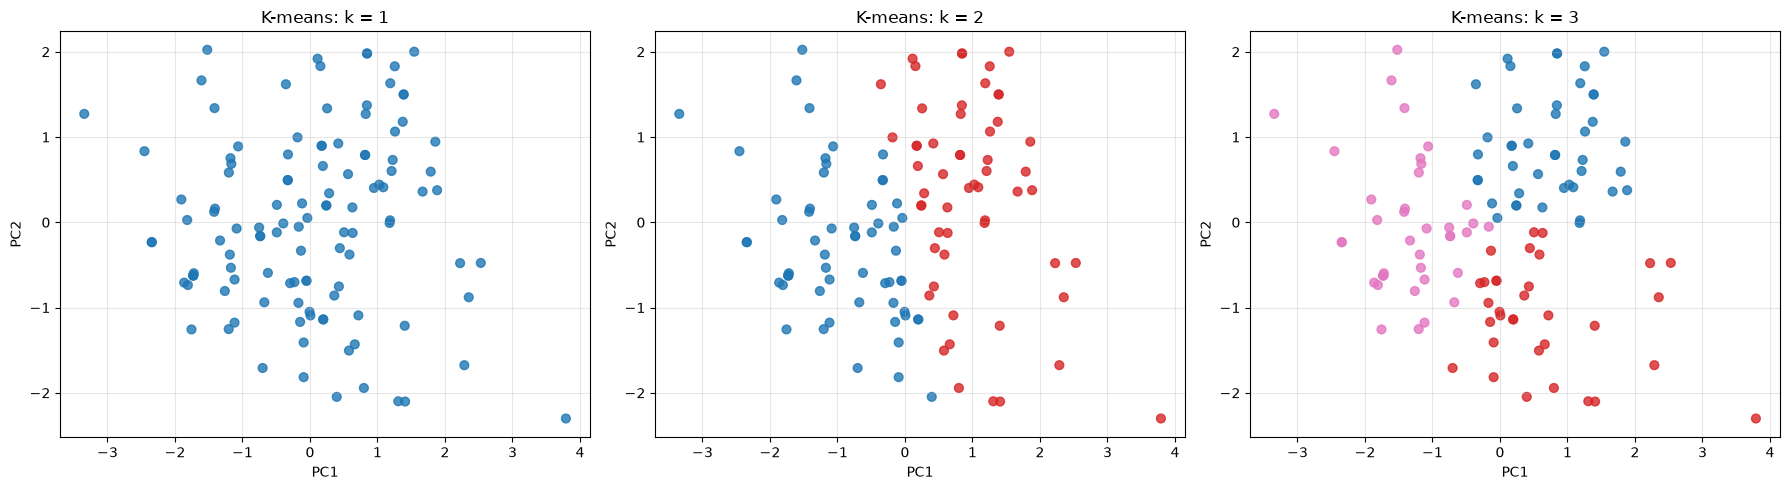

In [ ]:
fig, axes = plt.subplots(1, 3, figsize=(18, 5)) # графики для разных значений k
for ax, k in zip(axes, k_values): # # Перебор  графиков и результаты K-means
    labels = kmeans_results_hw[k]
    ax.scatter(X_pca_hw[:, 0],X_pca_hw[:, 1],c=labels, cmap="tab10", vmin=0, vmax=3,s=40,alpha=0.8)# поментка точек на проекции PCA по найденным кластерам
    ax.set_title(f"K-means: k = {k}")
    ax.set_xlabel("PC1")
    ax.set_ylabel("PC2")
    ax.grid(True, alpha=0.3)

plt.tight_layout()

fig.savefig(pics_save / "6_kmeans_comparison.png",dpi=300,bbox_inches="tight")

plt.show()

# 7. Сравнение исходного распределения и K-means в 3D

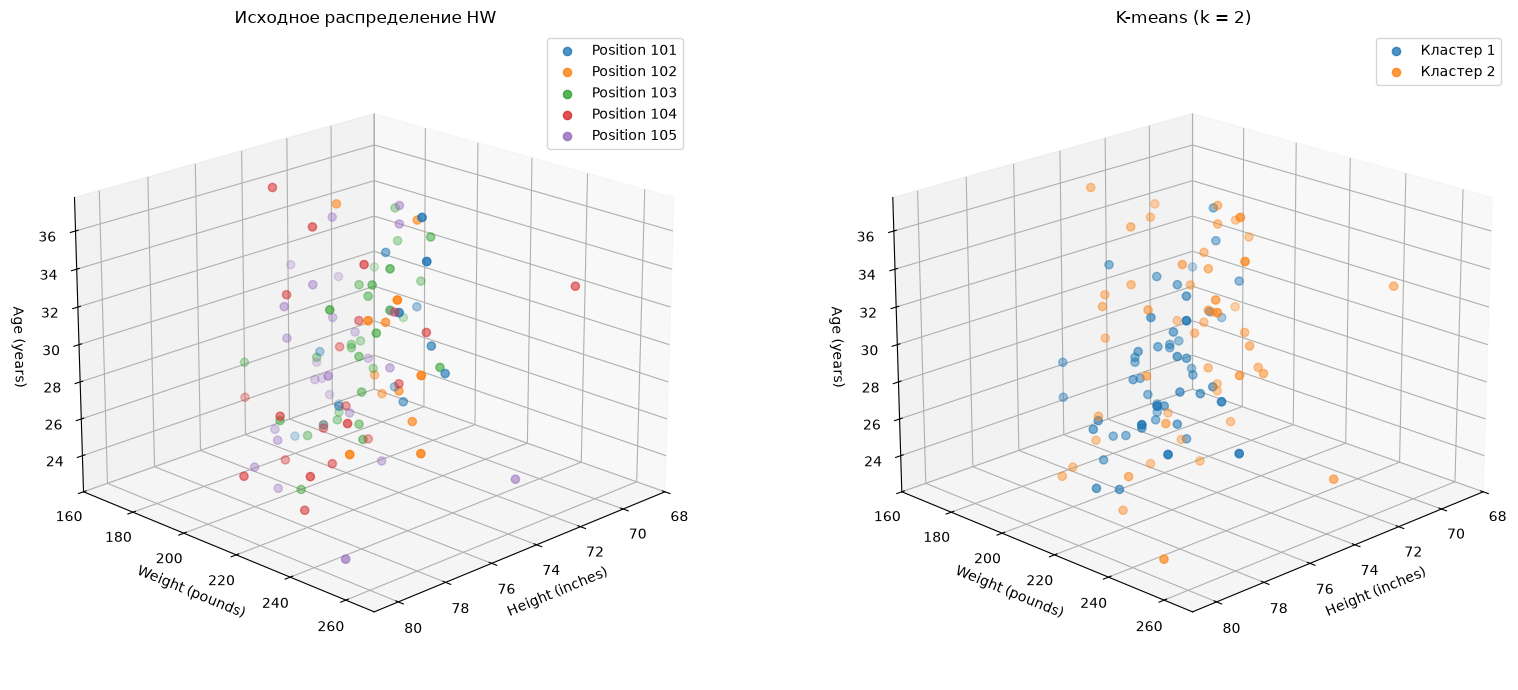

In [ ]:
import numpy as np
import matplotlib.pyplot as plt

original_positions = df["Position"].astype(int)
predicted_labels = kmeans_results_hw[2]
fig = plt.figure(figsize=(17, 7))

ax1 = fig.add_subplot(121, projection="3d")
ax2 = fig.add_subplot(122, projection="3d")

for position in sorted(original_positions.unique()):
    mask =original_positions == position
    ax1.scatter(df.loc[mask,"Height(inches)"],df.loc[mask, "Weight(pounds)"], df.loc[mask, "Age"],label=f"Position {position}", s=35, alpha=0.8)

for cluster in np.unique(predicted_labels): # результат K-means по найденным кластерам
    mask = predicted_labels == cluster # строки с текущей позицией

    #выбранные наблюдения по росту, весу и возрасту
    ax2.scatter(df.loc[mask, "Height(inches)"],df.loc[mask, "Weight(pounds)"], df.loc[mask, "Age"],label=f"Кластер {cluster + 1}", s=35,alpha=0.8)

for ax, title in zip([ax1, ax2], ["Исходное распределение HW", "K-means (k = 2)"]):
    ax.set_title(title)
    ax.set_xlabel("Height (inches)")
    ax.set_ylabel("Weight (pounds)")
    ax.set_zlabel("Age (years)")
    ax.set_xlim(df["Height(inches)"].min(), df["Height(inches)"].max())
    ax.set_ylim(df["Weight(pounds)"].min(), df["Weight(pounds)"].max())
    ax.set_zlim(df["Age"].min(), df["Age"].max())
    ax.view_init(elev=20, azim=45)
    ax.legend()

plt.tight_layout()

fig.savefig(pics_save / "7_3d_comparison.png",dpi=300,bbox_inches="tight")

plt.show()